# posterior-landscape — icon and wordmark

Reproduce the icon used in the viewer: two unequal peaks, a teal baseline,
and a rounded dark tile. The default coordinates, colours and stroke widths
are the original SVG's. This notebook needs **Matplotlib** and the usual
Jupyter display support; it reads no external files and makes no network requests.

**Run all cells.** The original icon and the icon with **posterior-landscape**
written beside it are saved in `logo_exports/`, in SVG, PNG and PDF. There is
no subtitle. The icon also has a transparent version; the wordmark has a dark
website-style version and a transparent version with dark letters for light pages.
SVG is the best choice for a repository or website; PNG is useful in slides.

The icon was drawn in code for this viewer. A limited visual comparison on
28 September 2026 found no exact match among the Mountain Equipment, MEC and
Millet logos inspected. Mountain/twin-peak motifs are common; this is not a
guarantee of uniqueness or trademark clearance.


## Settings

Colours and PNG resolution are editable here. Keep the point coordinates to preserve the original mark.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, PathPatch
from matplotlib.textpath import TextPath
from matplotlib.font_manager import FontProperties
from matplotlib.transforms import Affine2D
from IPython.display import Image, display

OUTPUT_DIR = Path("logo_exports")
PNG_PIXELS = 1024
WORDMARK_PNG_HEIGHT = 256

PEAK_COLOUR = "#f1b06c"
BASELINE_COLOUR = "#60dfce"
TILE_COLOUR = "#111326"

# Wordmark: same two-weight styling as the website, with the requested hyphen.
# DejaVu Sans ships with Matplotlib, so no font download is needed.
FONT_FAMILY = "DejaVu Sans"
FONT_SIZE = 18
WORDMARK_GAP = 10
WORDMARK_BACKGROUND = "#0b0f1a"  # Use "none" for transparent, light lettering.
WORDMARK_COLOURS = ("#eeeef5", "#ced4e2")
WORDMARK_LIGHT_COLOURS = ("#111326", "#454b60")

# Original geometry in a 32 × 32 square, with y increasing downward.
PEAK_POINTS = [(5, 24), (11, 10), (16, 19), (22, 6), (28, 24)]
BASELINE_POINTS = [(6, 26), (27, 26)]
PEAK_WIDTH = 2.3
BASELINE_WIDTH = 1.5
TILE_RADIUS = 9


## Draw the original geometry

The SVG stores the coordinates directly. Matplotlib uses the same geometry
for PNG and PDF, with stroke widths converted from the 32-unit canvas to points.
The wordmark uses Matplotlib's bundled DejaVu Sans, with a heavier **posterior**
and lighter **-landscape**. The browser's system font varies between computers;
this portable font preserves the two-weight style. Letters are exported as vector
outlines, so the saved files need no installed font or external asset.


In [2]:
def logo_svg(with_tile=True):
    """Editable vector source, using the viewer's original SVG geometry."""
    peak_path = "M" + " ".join(f"{x:g} {y:g}" for x, y in PEAK_POINTS)
    (x0, y0), (x1, y1) = BASELINE_POINTS
    tile = (
        f'<rect width="32" height="32" rx="{TILE_RADIUS:g}" fill="{TILE_COLOUR}"/>'
        if with_tile else ""
    )
    return (
        '<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 32 32" '
        'width="512" height="512" role="img" aria-label="Posterior Landscape">\n'
        '<title>Posterior Landscape</title>\n'
        f'{tile}\n'
        f'<path d="{peak_path}" fill="none" stroke="{PEAK_COLOUR}" '
        f'stroke-width="{PEAK_WIDTH:g}" stroke-linejoin="round" stroke-linecap="butt"/>\n'
        f'<path d="M{x0:g} {y0:g} L{x1:g} {y1:g}" fill="none" '
        f'stroke="{BASELINE_COLOUR}" stroke-width="{BASELINE_WIDTH:g}" '
        'stroke-linecap="butt"/>\n</svg>\n'
    )


def logo_figure(with_tile=True, canvas_width=32, background="none"):
    """Same icon geometry; optional extra horizontal space for the wordmark."""
    inches = 4
    fig = plt.figure(figsize=(inches * canvas_width / 32, inches), facecolor=background)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set(xlim=(0, canvas_width), ylim=(32, 0), aspect="equal")
    ax.set_axis_off()

    if with_tile:
        # Two rectangles plus circular corners form the SVG's rounded tile.
        r = TILE_RADIUS
        ax.add_patch(Rectangle((r, 0), 32 - 2*r, 32, color=TILE_COLOUR, linewidth=0))
        ax.add_patch(Rectangle((0, r), 32, 32 - 2*r, color=TILE_COLOUR, linewidth=0))
        for x in (r, 32 - r):
            for y in (r, 32 - r):
                ax.add_patch(Circle((x, y), r, color=TILE_COLOUR, linewidth=0))

    points_per_unit = inches * 72 / 32
    for vertices, colour, width in (
        (PEAK_POINTS, PEAK_COLOUR, PEAK_WIDTH),
        (BASELINE_POINTS, BASELINE_COLOUR, BASELINE_WIDTH),
    ):
        x, y = zip(*vertices)
        ax.plot(x, y, color=colour, linewidth=width * points_per_unit,
                solid_joinstyle="round", solid_capstyle="butt")
    return fig


def wordmark_figure(on_light=False):
    """Icon and 'posterior-landscape', vertically centred, without a subtitle."""
    first = TextPath((0, 0), "posterior", size=FONT_SIZE,
                     prop=FontProperties(family=FONT_FAMILY, weight="bold"))
    second = TextPath((0, 0), "-landscape", size=FONT_SIZE,
                      prop=FontProperties(family=FONT_FAMILY, weight="normal"))
    b1, b2 = first.get_extents(), second.get_extents()
    x1 = 32 + WORDMARK_GAP
    x2 = x1 + b1.x1 + 0.7
    width = x2 + b2.x1 + 6
    baseline = 16 + (min(b1.y0, b2.y0) + max(b1.y1, b2.y1)) / 2
    colours = WORDMARK_LIGHT_COLOURS if on_light else WORDMARK_COLOURS
    background = "none" if on_light else WORDMARK_BACKGROUND
    fig = logo_figure(canvas_width=width, background=background)
    ax = fig.axes[0]
    for path, x, colour in zip((first, second), (x1, x2), colours):
        transform = Affine2D().scale(1, -1).translate(x, baseline) + ax.transData
        ax.add_patch(PathPatch(path, transform=transform, facecolor=colour, linewidth=0))
    return fig


## Preview and save

Change the settings above and rerun to regenerate the files. Existing exports
with the same names are replaced. The transparent variant removes only the dark
tile; the coloured mark is unchanged. The wordmark on a light page keeps the
original icon and uses dark lettering. PDF and SVG remain vector graphics.


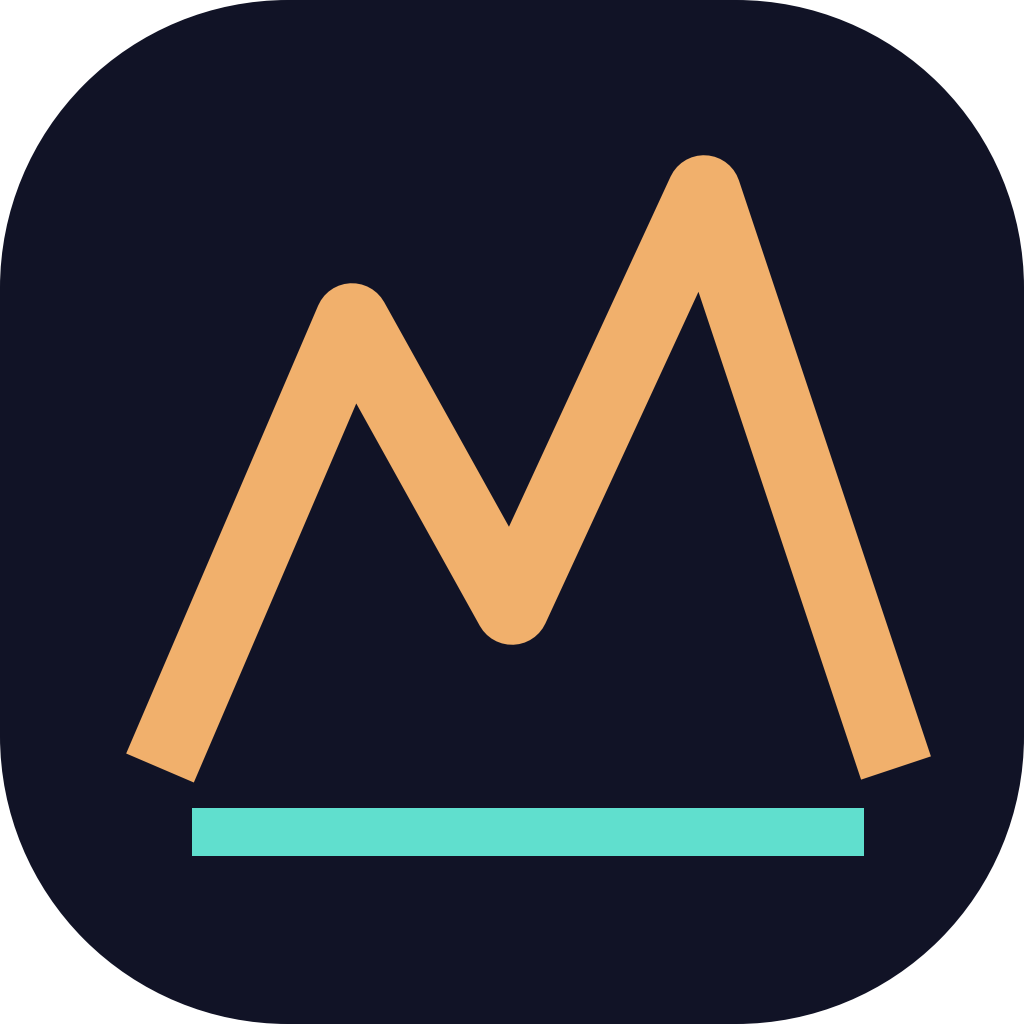

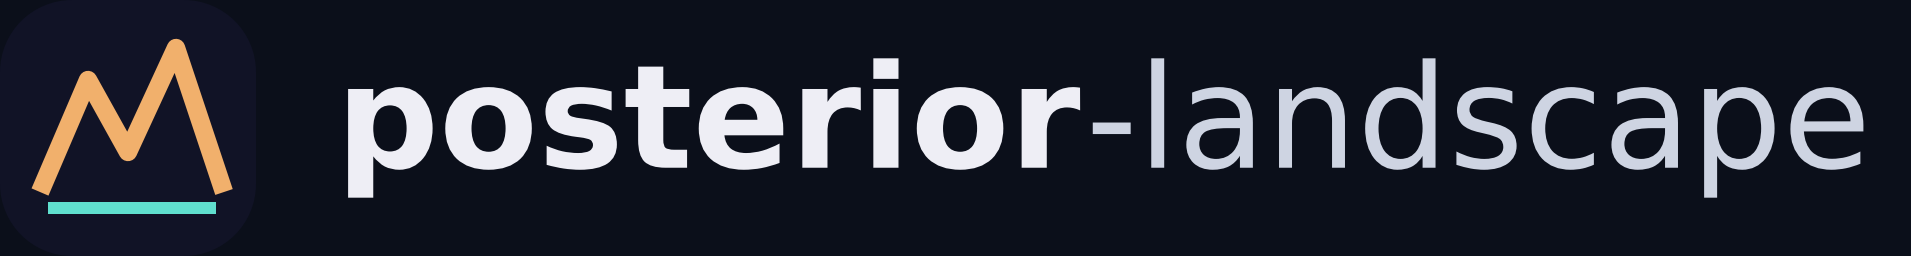

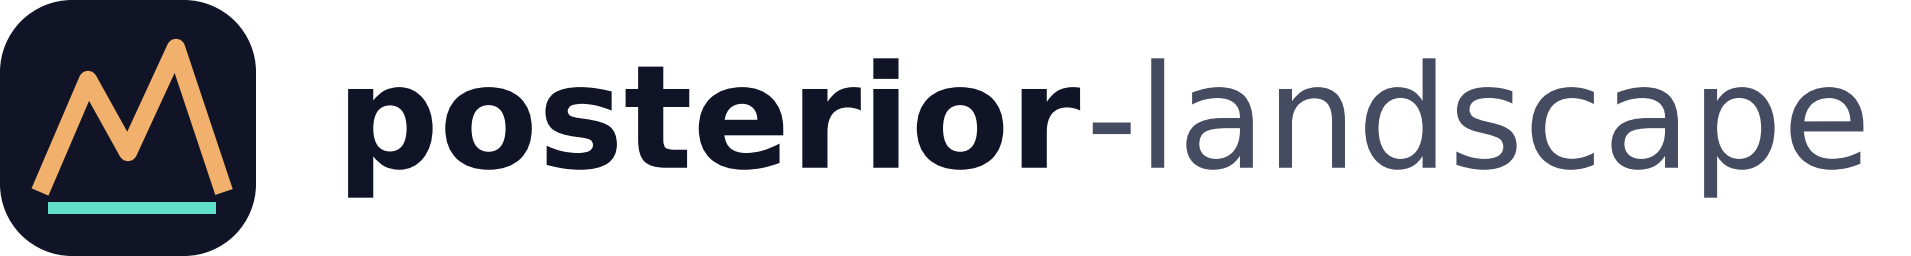

Saved icon + wordmark in SVG, PNG and PDF (12 files) in logo_exports/


In [3]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for with_tile, suffix in [(True, ""), (False, "_transparent")]:
    stem = OUTPUT_DIR / f"posterior_landscape_logo{suffix}"
    stem.with_suffix(".svg").write_text(logo_svg(with_tile), encoding="utf-8")
    fig = logo_figure(with_tile)
    fig.savefig(stem.with_suffix(".png"), dpi=PNG_PIXELS / 4,
                transparent=True, bbox_inches=None, pad_inches=0)
    fig.savefig(stem.with_suffix(".pdf"), transparent=True,
                bbox_inches=None, pad_inches=0)
    plt.close(fig)

for on_light, suffix in [(False, ""), (True, "_on_light")]:
    stem = OUTPUT_DIR / f"posterior_landscape_wordmark{suffix}"
    fig = wordmark_figure(on_light)
    transparent = on_light or WORDMARK_BACKGROUND == "none"
    for extension in ("svg", "png", "pdf"):
        fig.savefig(stem.with_suffix("." + extension), dpi=WORDMARK_PNG_HEIGHT / 4,
                    transparent=transparent, bbox_inches=None, pad_inches=0,
                    metadata={"Title": "posterior-landscape"})
    plt.close(fig)

display(Image(filename=str(OUTPUT_DIR / "posterior_landscape_logo.png"), width=128))
display(Image(filename=str(OUTPUT_DIR / "posterior_landscape_wordmark.png"), width=720))
display(Image(filename=str(OUTPUT_DIR / "posterior_landscape_wordmark_on_light.png"), width=720))
print(f"Saved icon + wordmark in SVG, PNG and PDF (12 files) in {OUTPUT_DIR.resolve()}")
